# Primer Proyecto EcoBicis en Ciudad Universitaria Lázaro Reynoso.

En este Proyecto se pondrán en práctica técnicas y metodologías de procesamiento, análisis, y predicción de datos usando el lenguaje de programación Python, trabajando sobre datasets del sistema EcoBici del Gobierno de la Ciudad de Buenos Aires.

Para ello, se requerirá importar los siguientes paquetes de Python:

In [1]:
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so
import numpy as np
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from formulaic import Formula

Antes de empezar a trabajar, vale la pena introducir brevemente el sistema EcoBici del Gobierno de la Ciudad de Buenos Aires, cuyos datasets se estarán analizando, para obtener un poco más de conocimiento de dominio.

### El sistema EcoBici

El sistema EcoBici del Gobierno de la Ciudad de Buenos Aires, administrado por la empresa privada Tembici desde 2019, funciona de acuerdo a lo que se detalla en estos links:
* https://buenosaires.gob.ar/gcaba_historico/infraestructura/movilidad/que-es-ecobici
* https://www.baecobici.com.ar/#/es/faq

En resumidas cuentas, el sistema permite a cualquier ciudadano retirar una bicicleta que se encuentre estacionada en algún puerto de cualquier estación para conducirla por hasta 30 minutos (con una tolerancia de 5 minutos; pasados los 30 minutos, se deberá pagar por el uso de la bicicleta). Una vez finalizado su uso, la bicicleta debe estacionarse en alguna estación, usando algún puerto que se encuentre vacante. 

En caso de detectar deficiencias en alguna bicicleta, los usuarios pueden solicitar mantenimiento dejándola estacionada en el algún puerto vacante y apretando el botón rojo de dicho puerto. Para informar problemas en el funcionamiento de una estación se pueden utilizar las vías de comunicación en la aplicación para teléfonos celulares y en el sitio web de la ciudad (http://www.baecobici.com.ar/). Para más información, consultar los incisos 4.6 y 4.10 de https://help-tembici-ecobici.zendesk.com/hc/es-419/articles/20940354553108-T%C3%A9rminos-y-condiciones.

A continuación se carga y muestra un vistazo del primer dataset sobre el cual se trabajará, que ofrece métricas de uso de las bicicletas del sistema en cada hora del día para dos estaciones, ubicadas en Ciudad Universitaria:

In [2]:
datos = pd.read_csv(
    "https://raw.githubusercontent.com/FedeGiovannetti/Eco_bici_Ciudad_Universitaria/refs/heads/main/data/full_data.csv"
)
datos

,station_id,num_bikes_available,num_bikes_disabled,num_docks_available,num_docks_disabled,last_reported,is_charging_station,status,is_installed,is_renting,is_returning,traffic,num_bikes_available_types.mechanical,num_bikes_available_types.ebike,Date,hora,dia
0,420,3,1,8,0,1.745880e+09,False,IN_SERVICE,1,1,1,NaN,3,0,2025-04-28,23:28:05,Monday
1,464,11,2,7,0,1.745894e+09,False,IN_SERVICE,1,1,1,NaN,11,0,2025-04-28,23:28:05,Monday
2,420,5,1,6,1,1.745897e+09,False,IN_SERVICE,1,1,1,NaN,5,0,2025-04-29,00:32:59,Tuesday
3,464,11,2,7,0,1.745898e+09,False,IN_SERVICE,1,1,1,NaN,11,0,2025-04-29,00:32:59,Tuesday
4,420,5,1,6,1,1.745900e+09,False,IN_SERVICE,1,1,1,NaN,5,0,2025-04-29,01:13:46,Tuesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13205,464,9,0,11,0,1.771886e+09,False,IN_SERVICE,1,1,1,NaN,9,0,2026-02-23,19:32:26,Monday
13206,420,0,0,12,0,1.771889e+09,False,IN_SERVICE,1,1,1,NaN,0,0,2026-02-23,20:27:32,Monday
13207,464,10,0,10,0,1.771889e+09,False,IN_SERVICE,1,1,1,NaN,10,0,2026-02-23,20:27:32,Monday
13208,420,0,0,12,0,1.771896e+09,False,IN_SERVICE,1,1,1,NaN,0,0,2026-02-23,22:17:13,Monday


Un inconveniente de este dataset es que desconocemos el significado de sus columnas (variables). Para obtener esta información se puede investigar el portal web de la API del Gobierno de la Ciudad para datos abiertos, que en https://api-transporte.buenosaires.gob.ar/console ofrece la información de este dataset dentro de la solapa $\texttt{ecobici/gbfs/StationStatus}$. Se puede ver en la información que se despliega que el sistema usa la *General Bikeshare Feed Specification (GBFS)*, cuyo sitio web está en https://gbfs.org/, y su repositorio de desarrollo en https://github.com/MobilityData/gbfs. Revisando este último repositorio, que indica que la última versión de esta especificación (GBFS) es la 3.0, se accede a un link que redirige a otro repositorio con la información, para esta última versión, del *JSON Schema*, en https://github.com/MobilityData/gbfs-json-schema/blob/master/v3.0/station_status.json. Finalmente, dentro del archivo expuesto por este último link, la información se encuentra en $\texttt{data:properties:stations:items:properties}$, donde cada ítem (del campo $\texttt{properties}$) representa una columna, con una descripción ubicada en su propio campo $\texttt{description}$. Las descripciones de las columnas con las que se trabajará a futuro se plasman en la siguiente tabla:

| Variable | Descripción |
| :--- | :--- |
| **`station_id`** | Identificador único de la estación de bicicletas. Entero de valor mínimo 0. |
| **`num_bikes_available`** | Número de bicicletas físicamente disponibles para alquilar en la estación. Entero de valor mínimo 0. |
| **`num_bikes_disabled`** | Número de bicicletas inhabilitadas en la estación. Entero de valor mínimo 0. |
| **`num_docks_available`** | Número de puertos funcionales físicamente en la estación. Entero de valor mínimo 0. |
| **`num_docks_disabled`** | Número de puertos vacíos pero inhabilitados en la estación. Entero de valor mínimo 0. |
| **`Date`** | Fecha de la observación. String en formato ISO $\texttt{YYYY-MM-DD}$. |
| **`hora`** | Hora de la observación. String en formato ISO $\texttt{hh:mm:ss}$. |
| **`dia`** | Día de la observación. String de valor $\texttt{Monday}$, $\texttt{Tuesday}$, $\texttt{Wednesday}$, $\texttt{Thursday}$, $\texttt{Friday}$, $\texttt{Saturday}$, o $\texttt{Sunday}$. |

Como se mencionó previamente, el dataset tiene recopilada información para dos estaciones en Ciudad Universitaria:

In [3]:
datos["station_id"].unique() # Valores únicos de la columna "station_id".

array([420, 464])

Dichas estaciones tienen ID = $\texttt{420}$ de nombre *375 - Ciudad Universitaria I*, ubicada en *INTENDENTE GUIRALDES 2610 - CERO MAS INFINITO* (el pabellón 0+Infinito de la FCEN, Facultad de Ciencias Exactas y Naturales), e ID = $\texttt{464}$ de nombre *377 - CIUDAD UNIVERSITARIA III*, ubicada en *Intendente Guiraldes 2160 - Pabellón III* (edificio de la Facultad de Diseño y Urbanismo, FADU) (información obtenida de la solapa $\texttt{ecobici/gbfs/stationInformation}$ en https://api-transporte.buenosaires.gob.ar/console, la interfaz web de la API del Gobierno de la Ciduad). 

## Procesamiento de datos

En esta sección se implementarán algunas acciones básicas de selección y procesamiento de datos.

In [4]:
datos_limpios = datos[
    ["station_id", "num_bikes_available","num_bikes_disabled","num_docks_available","num_docks_disabled","Date","hora","dia"]
] # Se filtran columnas relevantes para este analisis

display(datos_limpios) # Se muestra el dataset filtrado.

,station_id,num_bikes_available,num_bikes_disabled,num_docks_available,num_docks_disabled,Date,hora,dia
0,420,3,1,8,0,2025-04-28,23:28:05,Monday
1,464,11,2,7,0,2025-04-28,23:28:05,Monday
2,420,5,1,6,1,2025-04-29,00:32:59,Tuesday
3,464,11,2,7,0,2025-04-29,00:32:59,Tuesday
4,420,5,1,6,1,2025-04-29,01:13:46,Tuesday
...,...,...,...,...,...,...,...,...
13205,464,9,0,11,0,2026-02-23,19:32:26,Monday
13206,420,0,0,12,0,2026-02-23,20:27:32,Monday
13207,464,10,0,10,0,2026-02-23,20:27:32,Monday
13208,420,0,0,12,0,2026-02-23,22:17:13,Monday


Como los nombres de las columnas están en inglés, se los traduce a español para trabajar más cómodamente:

In [5]:
# Se utiliza un diccionario cuyas claves son los nombres originals y cuyo valores son los nombres nuevos para 
# renombrar a las columnas (y así traducirlas del inglés al español):
datos_limpios = datos_limpios.rename(columns={
    "station_id" : "estacion", 
    "num_bikes_available" : "bicis_disponibles", 
    "num_bikes_disabled" : "bicis_rotas", 
    "num_docks_available" : "puertos_disponibles", 
    "num_docks_disabled" : "puertos_rotos", 
    "Date" : "fecha", 
    "hora" : "horario", 
    "dia" : "dia_semana"
})

display(datos_limpios) # Se muestra el dataset con los nombres de columnas traducidos al español.

,estacion,bicis_disponibles,bicis_rotas,puertos_disponibles,puertos_rotos,fecha,horario,dia_semana
0,420,3,1,8,0,2025-04-28,23:28:05,Monday
1,464,11,2,7,0,2025-04-28,23:28:05,Monday
2,420,5,1,6,1,2025-04-29,00:32:59,Tuesday
3,464,11,2,7,0,2025-04-29,00:32:59,Tuesday
4,420,5,1,6,1,2025-04-29,01:13:46,Tuesday
...,...,...,...,...,...,...,...,...
13205,464,9,0,11,0,2026-02-23,19:32:26,Monday
13206,420,0,0,12,0,2026-02-23,20:27:32,Monday
13207,464,10,0,10,0,2026-02-23,20:27:32,Monday
13208,420,0,0,12,0,2026-02-23,22:17:13,Monday


Se puede notar que los valores de la columna **`dia_semana`** (originalmente **`dia`**) son strings (cadenas de caracteres) que están en inglés. Siguiendo la lógica del inciso 2, se traduce estos valores al español para aún mayor comodidad al trabajar:

In [6]:
# Se utiliza la función "map" para "mapear" los valores originales (claves, a la izquierda en la definición del 
# diccionario) a los nuevos (valores, a la derecha en la definición diccionario).
datos_limpios["dia_semana"] = datos_limpios["dia_semana"].map({
    "Monday" : "Lunes", 
    "Tuesday" : "Martes", 
    "Wednesday" : "Miercoles", 
    "Thurdsay" : "Jueves", 
    "Friday" : "Viernes", 
    "Saturday" : "Sabado", 
    "Sunday" : "Domingo"
})

display(datos_limpios) # Se muestra el dataset con los valores de la columna "dia_semana" en español.

,estacion,bicis_disponibles,bicis_rotas,puertos_disponibles,puertos_rotos,fecha,horario,dia_semana
0,420,3,1,8,0,2025-04-28,23:28:05,Lunes
1,464,11,2,7,0,2025-04-28,23:28:05,Lunes
2,420,5,1,6,1,2025-04-29,00:32:59,Martes
3,464,11,2,7,0,2025-04-29,00:32:59,Martes
4,420,5,1,6,1,2025-04-29,01:13:46,Martes
...,...,...,...,...,...,...,...,...
13205,464,9,0,11,0,2026-02-23,19:32:26,Lunes
13206,420,0,0,12,0,2026-02-23,20:27:32,Lunes
13207,464,10,0,10,0,2026-02-23,20:27:32,Lunes
13208,420,0,0,12,0,2026-02-23,22:17:13,Lunes


Una vez realizadas las modificaciones al dataset para mayor conveniencia, se pueden dar los primeros pasos en analizar el dataset. En particular, una de las primeras cosas que pueden revisarse son los tipos de los datos (es decir, el tipo de los valores de las columnas), para poder determinar, entre otras cosas, qué tipo de operaciones se pueden hacer con ellos:

In [7]:
print(datos_limpios.info()) # Muestra un resumen con información de la dataframe "datos_limpios". 
# print(datos_limpios.dtypes) # también se puede usar la función "dtypes".

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13210 entries, 0 to 13209
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   estacion             13210 non-null  int64 
 1   bicis_disponibles    13210 non-null  int64 
 2   bicis_rotas          13210 non-null  int64 
 3   puertos_disponibles  13210 non-null  int64 
 4   puertos_rotos        13210 non-null  int64 
 5   fecha                13210 non-null  object
 6   horario              13210 non-null  object
 7   dia_semana           11320 non-null  object
dtypes: int64(5), object(3)
memory usage: 825.8+ KB
None


Las columnas **`fecha`**, **`horario`** y **`dia_semana`** son de tipo $\texttt{object}$, un "comodín" que puede representar varios tipos distintos. Para obtener más detalle, se consulta específicamente por el tipo de estas columna, inspeccionando el tipo del valor en su primera fila:

In [8]:
for nombre_columna in ["fecha", "horario", "dia_semana"]:
    print("Tipo de los valores en la columna " + nombre_columna + ": ", type(datos_limpios[nombre_columna][0]))

Tipo de los valores en la columna fecha:  <class 'str'>
Tipo de los valores en la columna horario:  <class 'str'>
Tipo de los valores en la columna dia_semana:  <class 'str'>


Parece entonces que el tipo de los valores de estas últimas tres columnas es en realidad $\texttt{string}$. Se concluye entonces que los tipos de las variables (columnas) son los siguientes:
* Las variable **`estacion`**, **`bicis_disponibles`**, **`bici_rotas`**, **`puertos_disponibles`**, **`puertos_rotos`** son numéricas y discretas, al ser números enteros (tipo $\texttt{int64}$) que representan cantidades o identificadores de entidades.
* La variable **`horario`** es (conceptualmente) numérica y continua, al representar un horario (en formato $\texttt{string}$) en el rango de 24 horas, que podría considerarse continuo, dado que puede "afinarse" como se necesite (a la hora, al minuto, al segundo, a la milésima de segundo, etc.).
* La variable **`dia_semana`** es categórica y ordinal, ya que es una $\texttt{string}$ puede adoptar una cantidad muy limitada de valores no numéricos (Lunes, Martes, Miércoles, Jueves, Viernes, Sábado o Domingo), pero con un orden relativo entre sí.
* La variable **`fecha`** es (conceptualmente) numérica y discreta, al representar, a fin de cuentas, algún entero (codificado mediante una $\texttt{string}$) en el rango desde 1 hasta 365 (correspondiente a los días del año).


Puede notarse que, entre otros datos, la consola informa que todas las variables tienen 13206 datos no nulos, salvo por **`dia_semana`**, que tiene sólo 11318. Esto amerita investigarse un poco más en detalle, dado que los datos faltantes pueden causar inconvenientes al momento de explorar, analizar y procesar un dataset:

In [9]:
# Indica cuántos NaNs hay en el data set en cada columna. La función isnull devuelve un "array" de booleanos según 
# si el dato correspondiente a su posición es NaN (True) o no (False), que luego se suma (tomando True = 1 y 
# False = 0) para obtener el total de valores ausentes:
print(datos_limpios.isnull().sum())

estacion                  0
bicis_disponibles         0
bicis_rotas               0
puertos_disponibles       0
puertos_rotos             0
fecha                     0
horario                   0
dia_semana             1890
dtype: int64


Como se sospechaba, hay valores ausentes en **`dia_semana`**, concretamente 1890. A continuación se muestra exactamente cuáles son los días de esta columna que faltan, consultando los valores correspondientes en la columna **`fecha`**:

In [10]:
print(datos_limpios[datos_limpios["dia_semana"].isnull()]["fecha"].unique()) # ¿Qué dias faltan?

['2025-05-01' '2025-05-08' '2025-05-15' '2025-05-22' '2025-05-29'
 '2025-06-05' '2025-06-12' '2025-06-19' '2025-06-26' '2025-07-03'
 '2025-07-10' '2025-07-17' '2025-07-24' '2025-07-31' '2025-08-07'
 '2025-08-14' '2025-08-21' '2025-08-28' '2025-09-04' '2025-09-11'
 '2025-09-18' '2025-09-25' '2025-10-02' '2025-10-09' '2025-10-16'
 '2025-10-23' '2025-10-30' '2025-11-06' '2025-11-13' '2025-11-20'
 '2025-11-27' '2025-12-04' '2025-12-11' '2025-12-18' '2025-12-25'
 '2026-01-01' '2026-01-08' '2026-01-15' '2026-01-22' '2026-01-29'
 '2026-02-05' '2026-02-12' '2026-02-19']



Dado que las columnas **`fecha`** y **`horario`** contienen valores más bien complejos con los que es difícil operar en formato $\texttt{string}$, se generan nuevas columnas numéricas **`anio`**, **`mes`**, **`dia`** y **`hora`** a partir de ellas para trabajar de forma más conveniente:

In [11]:
# Se separa a las strings en "fecha" entre cada caracter "-" (que separa el año, mes y día) 
# y se asigna las tres porciones a nuevas columnas "anio", "mes" y "dia":
datos_limpios[["anio","mes","dia"]] = datos_limpios["fecha"].str.split("-",expand=True)

# Como las porciones en "anio", "mes" y "dia" quedan en formato string, se las convierte a enteros:
datos_limpios["anio"] = datos_limpios["anio"].astype(int)
datos_limpios["mes"] = datos_limpios["mes"].astype(int)
datos_limpios["dia"] = datos_limpios["dia"].astype(int)

# Se el procedimiento par ala columna "horario", separando ahora por el caracter ":" (que separara a 
# las horas, los minutos y los segundos, de los cuales interesan sólo las horas).
datos_limpios["hora"] = datos_limpios["horario"].str.split(":", expand=True)[0] # Se indexa en 0 para las horas.
datos_limpios["hora"] = datos_limpios["hora"].astype(int) # Se convierte las horas a enteros.

print(datos_limpios.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13210 entries, 0 to 13209
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   estacion             13210 non-null  int64 
 1   bicis_disponibles    13210 non-null  int64 
 2   bicis_rotas          13210 non-null  int64 
 3   puertos_disponibles  13210 non-null  int64 
 4   puertos_rotos        13210 non-null  int64 
 5   fecha                13210 non-null  object
 6   horario              13210 non-null  object
 7   dia_semana           11320 non-null  object
 8   anio                 13210 non-null  int64 
 9   mes                  13210 non-null  int64 
 10  dia                  13210 non-null  int64 
 11  hora                 13210 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 1.2+ MB
None


Notar que las nuevas columnas son todas de tipo numérico ($\texttt{int64}$).


Además de crear las nuevas columnas, convendría también transformar las strings en las columnas **`fecha`** y **`horario`** a un nuevo formato dentro de las columnas mismas, que sea más apto para operar con sus valores. Una alternativa a dejarlos como $\texttt{strings}$ es convertirlos a formatos de tipo $\texttt{datetime}$ (y sus derivados), que están diseñados para trabajar con fechas y horarios:

In [12]:
datos_limpios["fecha"] = pd.to_datetime(datos_limpios["fecha"])
# Se saca el día de semana del datetime (en columna "fecha") y se coloca en la columna "dia_semana"
# (traducción al castellano mediante) para las filas en que "dia_semana" no tenga valores:
datos_limpios.loc[datos_limpios["dia_semana"].isnull(), "dia_semana"] = (
    datos_limpios[datos_limpios["dia_semana"].isnull()]["fecha"].
        apply(lambda d: d.weekday()).map(
            {0:"Lunes", 1:"Martes", 2:"Miercoles", 3:"Jueves", 4:"Viernes", 5:"Sabado", 6:"Domingo"}
        )
)
# Lo más cercano a "datos_limpios["hora"] = pd.to_datetime(datos_limpios["hora"]).dt.time" que funciona
# (se transforma a la columna "horario" a tipo datetime.time):
# datos_limpios["horario"] = datos_limpios["horario"].apply(datetime.time.fromisoformat)

for nombre_columna in ["fecha", "horario"]:
    print("Tipo de los valores en la columna " + nombre_columna + ": ", type(datos_limpios[nombre_columna][0]))

Tipo de los valores en la columna fecha:  <class 'pandas._libs.tslibs.timestamps.Timestamp'>
Tipo de los valores en la columna horario:  <class 'str'>



Eventualmente nos resultará informativo conocer la estación del año en la que se realizaron las mediciones (observaciones) el dataset. Para tal propósito, se define la siguiente función que recibe un $\texttt{DataFrame}$ de $\texttt{Pandas}$ y le agrega una columna **`estacion_anio`** con la estación del año en que se realizó la observación (o sea, la estación del año correspondiente a cada fila), usando la columna **`fecha`**, que se asume está en formato $\texttt{Timestamp}$ de $\texttt{Pandas}$ (usado para la conversión de la columna **`fecha`** en el inciso 7):

In [13]:
def estacion_de_timestamp_arg(ts):
    # Asume que ts es de tipo Timestamp de Pandas.
    inicio_otonio    = pd.Timestamp(ts.year,  3, 21)
    inicio_invierno  = pd.Timestamp(ts.year,  6, 21)
    inicio_primavera = pd.Timestamp(ts.year,  9, 21)
    inicio_verano    = pd.Timestamp(ts.year, 12, 21)
    estacion = "Verano"
    if inicio_otonio <= ts < inicio_invierno:
        estacion = "Otoño"
    elif inicio_invierno <= ts < inicio_primavera:
        estacion = "Invierno"
    elif inicio_primavera <= ts < inicio_verano:
        estacion = "Primavera"
    return estacion

def determinar_estacion_anio(datos):
    # Requiere que "datos" sea una DataFrame con columna "fecha" 
    # de tipo Timestamp de Pandas.
    datos["estacion_anio"] = datos["fecha"].apply(estacion_de_timestamp_arg)

## Análisis descriptivo

En esta sección se dará un primer análisis del dataset, usando distintos gráficos y medidas de resumen. 


Un primer análisis más detallado deldataset puede darse estudiando los promedios de bicicletas disponibles, de bicicletas rotas y de puertos disponibles por hora. Para tal fin, se genera un nuevo dataset en base al preexistente, agrupado por **`fecha`** y **`hora`**, que contiene nuevas columnas **`cantidad_bicis_disponibles`**, **`cantidad_bicis_rotas`**, **`cantidad_puertos_disponibles`**, y conserva las columnas **`fecha`**, **`hora`**, **`dia_semana`**, **`dia`**, **`mes`** y **`anio`**:

In [14]:

datos_agrupados = (
    datos_limpios.groupby(["fecha", "hora", "dia_semana", "anio", "mes", "dia"], as_index=False).
    agg(**{
        "cantidad_bicis_disponibles" : pd.NamedAgg(column="bicis_disponibles", aggfunc="sum"), 
        "cantidad_bicis_rotas" : pd.NamedAgg(column="bicis_rotas", aggfunc="sum"), 
        "cantidad_puertos_disponibles" : pd.NamedAgg(column="puertos_disponibles", aggfunc="sum")
    })
)
# Nota: El "groupby" agrupa no sólo por "fecha" y "hora", sino también por "dia_semana", "dia", 
# "mes" y "anio" para que no se pierdan estas otras últimas cuatro columnas, y porque agrupar   
# sólo por las primeras dos o por todas es lo mismo (si "fecha" y "hora" coinciden, entonces sólo  
# puede haber un valor posible para "dia_semana", "dia", "mes" y "anio" (de modo que agrupar  
# también por estas cuatro no filtra más filas del resultado)). 

# Tener en cuenta que la cantidad de filas del dataset agrupado será la mitad del dataset original, 
# porque se hace una medición (fila) por hora de cada día, pero hay dos estaciones. Lo que ocurre 
# entonces al agrupar for fecha y hora es que quedan agrupados en cada fecha y hora los datos de 
# las dos estaciones (y nada más), como sugiere el enunciado.

display(datos_agrupados)

,fecha,hora,dia_semana,anio,mes,dia,cantidad_bicis_disponibles,cantidad_bicis_rotas,cantidad_puertos_disponibles
0,2025-04-28,23,Lunes,2025,4,28,14,3,15
1,2025-04-29,0,Martes,2025,4,29,16,3,13
2,2025-04-29,1,Martes,2025,4,29,16,3,13
3,2025-04-29,2,Martes,2025,4,29,16,3,13
4,2025-04-29,3,Martes,2025,4,29,16,3,13
...,...,...,...,...,...,...,...,...,...
6600,2026-02-23,17,Lunes,2026,2,23,10,0,22
6601,2026-02-23,18,Lunes,2026,2,23,11,0,21
6602,2026-02-23,19,Lunes,2026,2,23,9,0,23
6603,2026-02-23,20,Lunes,2026,2,23,10,0,22



Con el dataset ya agrupado por **`fecha`** y **`hora`**, se puede analizar en qué estación del año hay más bicicletas disponibles, usando gráficos y la función definida para el inciso 8:

,estacion_anio,cantidad_bicis_disponibles
0,Invierno,11.776511
1,Otoño,12.110084
2,Primavera,4.885238
3,Verano,7.243741


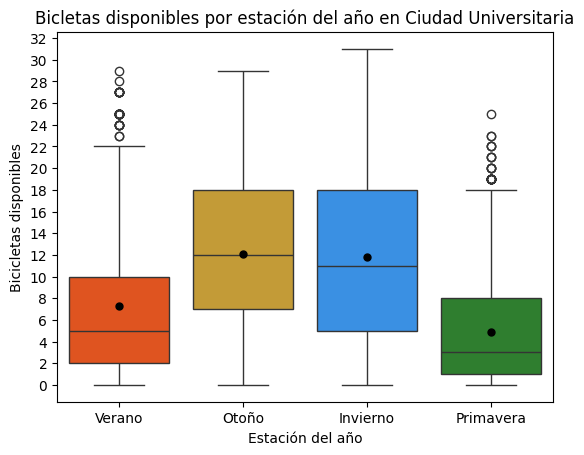

In [15]:
# Una respuesta numérica simple podría ser la siguiente, usando el promedio como medida de  
# resumen para cada estación:
determinar_estacion_anio(datos_agrupados)
display(datos_agrupados.groupby(["estacion_anio"], as_index=False).agg({"cantidad_bicis_disponibles" : "mean"}))

# Una respuesta visual se podría obtener con un boxplot:
axs = sns.boxplot(
    data=datos_agrupados, x="estacion_anio", y="cantidad_bicis_disponibles", hue="estacion_anio", 
    palette={"Verano":"orangered","Otoño":"goldenrod","Invierno":"dodgerblue","Primavera":"forestgreen"}, 
    order=["Verano", "Otoño", "Invierno", "Primavera"], 
    # kwargs (de matplotlib) para mostrar la media en cada caja:
    showmeans=True, meanprops={'marker':'o','markeredgecolor':'black','markerfacecolor':'black','markersize':'5'}
)
axs.set_xlabel("Estación del año")
axs.set_ylabel("Bicicletas disponibles")
axs.set_yticks(np.arange(datos_agrupados["cantidad_bicis_disponibles"].min(), 
                         datos_agrupados["cantidad_bicis_disponibles"].max() + 2, 2))
axs.set_title("Bicletas disponibles por estación del año en Ciudad Universitaria");
# ";" para suprimir output.

Tener en cuenta que los puntos negros en el boxplot representan la media para cada estación.

<details>
  <summary><b>Cliquear acá para expandir/colapsar el análisis de la disponibilidad de bicicletas en las estaciones</b></summary>

En el boxplot se puede observar que el promedio de la disponibilidad de bicicletas es generalmente menor en verano y primavera, y mayor en otoño e invierno. La alta disponibilidad en otoño se podría explicar fácilmente por su coincidencia con la mayoría del primer cuatrimestre (tradicionalmente uno de los períodos más activos en Ciudad Universitaria, entre otras razones porque es aquel en que comienzan a cursar la mayoría de los ingresantes a las facultades). La baja disponibilidad en verano es similarmente fácil de explicar, dado que coincide con el fin de clases, el receso de verano (en que no se dictan clases) y el período de cursos de verano (con, habitualmente, mucha menos actividad que los cursos dictados en el resto del año, entre otras razones por la oferta más limitada de cursos y horarios), lo cual provoca que haya menos actividad en Ciudad Universitaria y en consecuencia menos gente entrando y saliendo del campus (con o sin bicicletas). Tener en cuenta que, como se verá más adelante, las últimas horas del día muestran una disponibilidad de bicicletas mínima (ya que deja de ingresar gente con bicicletas, y los que ingresaron con bicicletas previamente probablemente las usan también para salir). Esto significa que durante el verano no quedan generalmente bicicletas estacionadas que hayan sido traídas en el resto del año, e ingresan (y quedan estacionadas) pocas por la relativamente baja actividad en el campus.

Por otro lado, la menor disponibilidad promedio en primavera es más difícil de explicar, ya que no coincide con ningún evento o período del calendario académico que naturalmente, de por sí, conduzca a menor actividad (y, por consiguiente, a menor disponibilidad de bicicletas, al haber en tal caso menos gente ingresando al campus (que, de llegar con bicicletas, las dejarían estacionadas)). Más aún, durante la primavera se desarrolla la mayoría del segundo cuatrimestre (y cuarto bimestre) en la FCEN (desde el 18/8 hasta el 6/12 en 2025$^1$), y la mayoría del segundo cuatrimestre de FADU (aproximadamente desde el 11/8 hasta el 4/12 en 2025$^2$), de modo que, de buenas a primeras, podría haberse esperado que la disponibilidad de bicicletas fuera similar a la de otoño, por desarrollarse durante el mismo la mayoría del primer cuatrimestre (que es, académica e institucionalmente, de características similares al segundo cuatrimestre). Una posible hipótesis es que la baja disponibilidad se deba a una batería de factores:
* El período de aproximadamente 15 días sin clases (y, por ende, baja actividad) al final de la primavera (la cual comienza en el 21/9 y finaliza en el 20/12).
* El ausentismo y la deserción estudiantil, que, junto a una baja en la cantidad de ingresantes a la facultad, posiblemente se pronuncien en el segundo cuatrimestre. Que hay menos ingresantes en los segundos cuatrimestres es un fenómeno relativamente conocido, ya que el sistema educativo está generalmente organizado por años, y resulta razonable pensar que el estudiante promedio busca avanzar al próximo estadío educativo tan pronto como le sea posible (que suele ser en el primer cuatrimestre del año siguiente al del CBC). Que haya mayor ausentismo y deserción, sin embargo, es una aseveración más difícil de verificar, al no haber una razón clara ni datos abiertos que se puedan consultar al respecto. Se podría aventurar a hipotetizar que, por ejemplo, los estudiantes que ingresaron en el primer cuatrimestre ya ganan confianza para el inicio del segundo, y por ende son más proclives a ausentarse (lo cual, a su vez, podría contribuir a que eventualmente abandonen sus estudios). Otra podría resultar del pasaje del "efecto novedad"$^3$ del primer cuatrimestre (al llegar el segundo, la "novedad" de la experiencia pasó, y un estudiante podría sentirse menos inclinado a asistir a clases), aunque esto último probablemente aplique a sólo una minoría del alumnado. Por último, podría deberse a la dificultad académica de los cursos dictados en la facultad, que haría que el estudiante, viendo frustrados sus intentos de seguir las clases en el primer cuatrimestre, finalmente desista y se ausente en el segundo.
* Los patrones de contratación de las empresas, que suelen buscar candidatos (incluyendo estudiantes universitarios) durante los primeros trimestres del año fiscal (desde Q1 hasta Q3, coincidiendo generalmente con el primer cuatrimestre académico, y el inicio del segundo). Esto podría provocar que, al llegar el cuarto trimestre fiscal (Q4, que se solapa principalmente con la primavera), ya haya una porción significativa de los estudiantes que pasaron los procesos de selección, y que, al ser finalmente contratados e incorporados a las empresas, progresivamente comiencen a ausentarse a las clases (dada la dificultad de sostener el estudio y el trabajo en paralelo). En otras palabras, el ausentismo debido a la carga dual de estudio y trabajo podría materializarse en primavera.
* Los patrones de carga laboral que imponen las empresas sobre sus trabajadores (entre los cuales hay estudiantes universitarios), que suelen ser más exigidos durante el cuarto y último trimestre fiscal (Q4), porque es ahí donde se presenta la última oportunidad para cumplir con los objetivos financieros anuales. Esto podría provocar que los estudiantes que trabajan salgan más cansados, más tarde o con tareas pendientes del trabajo, provocando así una menor intención de asistir a clases.

Tener en cuenta, además, que todas las posibles causas con origen en la esfera de lo laboral se pronunciarían en carreras específicas como las licenciaturas en Computación y Ciencias de Datos, cuyos alumnos (que componen una porción significativa de todo el alumnado de la FCEN$^4$) suelen comenzar a trabajar más temprano que los de otras carreras (generalmente por una combinación de ventajas relativas, entre las que se incluyen salarios más competitivos, mayor oferta laboral y menores barreras de aceptación). Por otro lado, si bien hubo una cantidad no insignificante de paros docentes durante 2025 (debido a la emergencia salarial y presupuestaria), esto no parece haberse presentado de forma especialmente pronunciada durante la primavera, de modo que no parecería explicar la disponibilidad de bicicletas particularmente baja en esta estación del año.

Por su parte, y a pesar de coincidir con un receso y el fin del primer cuatrimestre, invierno presenta alta disponibilidad, lo cual podría deberse principalmente a que una mayor cantidad de estudiantes opte por regresar del campus por otros medios de transporte que ofrezcan mayor protección ante el frío (quedando así las bicicletas estacionadas en Ciudad Universitaria por más tiempo). Contribuye también positivamente a la actividad de invierno la existencia de los cursos de invierno (aunque por lo general tienen poca participación) y el inicio del segundo cuatrimestre.

Por último, observar que la caja de otoño presenta un rango amplio pero proporcional de valores (las distancias entre los cuantiles y la longitud de los bigotes es más o menos proporcional, y la media está bastante cerca de la mediana), propio de un período con continua actividad. Invierno, en cambio, presenta una mayor amplitud de valores, lo cual es de esperar, dado que es atravesado por varios ciclos de actividad e inactividad (fin del primer cuatrimestre, receso de invierno, cursos de invierno, e inicio del segundo cuatrimestre). Notar, por otro lado, que verano y primavera muestran rangos más dispares (con bigotes más largos, distancias intercuartiles más variadas, mayores distancias entre media y mediana, y más valores atípicos), propio de períodos con menor actividad, o actividad menguante (como podría ser el caso de primavera).

1. Según https://exactas.uba.ar/wp-content/uploads/2025/02/Almanaque2025.pdf .
2. Según https://www.fadu.uba.ar/calendarios-academicos-2025/ .
3. Para más información, consultar https://en.wikipedia.org/wiki/Novelty_effect .
4. Alrededor del 35% de los estudiantes de la FCEN en 2023 fueron de la Licenciatura en Ciencias de la Computación o la Licenciatura en Ciencias de Datos. Este dato fue derivado de la información en https://informacionestadisticauba.rec.uba.ar/facultades/m, solapa *Estudiantes por carrera y género*. Para filtrar sólo las carreras de la FCEN, se usó el listado provisto en https://informacionestadisticauba.rec.uba.ar/oferta-academica/, en la solapa *Facultad de Ciencias Exactas y Naturales*.


Etrando más en detalle, puede analizarse cómo cambia la cantidad promedio de bicis y puertos disponibles a lo largo del día, para cada día de la semana. Primero se analiza la cantidad promedio de bicicletas:

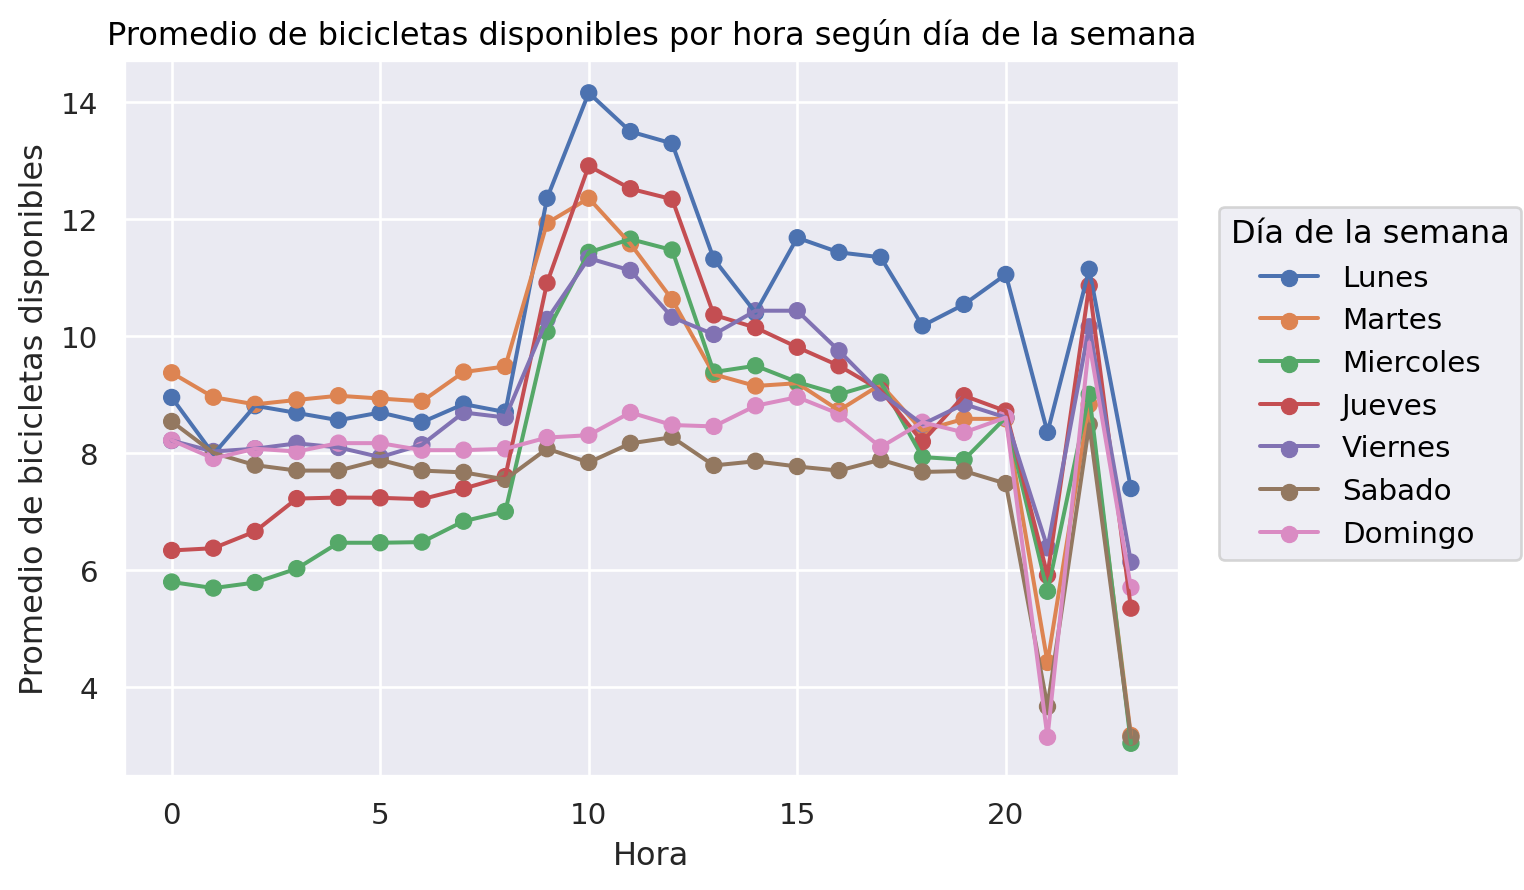

In [16]:
(
    so.Plot(data=datos_agrupados, x="hora", color="dia_semana")
    .add(so.Line(), so.Agg("mean"), y="cantidad_bicis_disponibles")
    .add(so.Dot(), so.Agg("mean"), y="cantidad_bicis_disponibles")
    .label(
        x="Hora",
        y="Promedio de bicicletas disponibles",
        title="Promedio de bicicletas disponibles por hora según día de la semana",
        color="Día de la semana"
    )
)

Lo que se observa es un conjunto de líneas de disponibilidad que parece reflejar, en general, el flujo de ingreso y egreso de estudiantes asistiendo a clases en tres turnos: mañana, tarde y noche. En particular, se pueden identificar tres picos, alrededor de las 10, 15 y 19 o 20 hs. (probablemente coincidiendo con la llegada de estudiantes a las clases), y tres mesetas alrededor de las 14, 18, y 21 o 23 hs. (probablemente coincidiendo con la salida de estudiantes de las clases). Este patrón se presenta claramente en los días Lunes a Viernes, mientras que, por otro lado, los días Sábado y Domingo presentan curvas más bien constantes a lo largo del día (consistente con el hecho de que las clases se dictan casi exclusivamente de Lunes a Viernes).

Por otro lado, se espera que las curvas de disponibilidad de puertos sean un "espejo" o "inversión" de las curvas de disponibilidad de bicicletas, dado que una bicicleta disponible es un puerto ocupado (no disponible), y una bicicleta que deja de estar disponible es un puerto que se desocupa (se vuelve disponible). Esto puede verificarse con el siguiente gráfico, mediante el cual se puede analizar el promedio de puertos disponibles por hora para cada día de la semana:

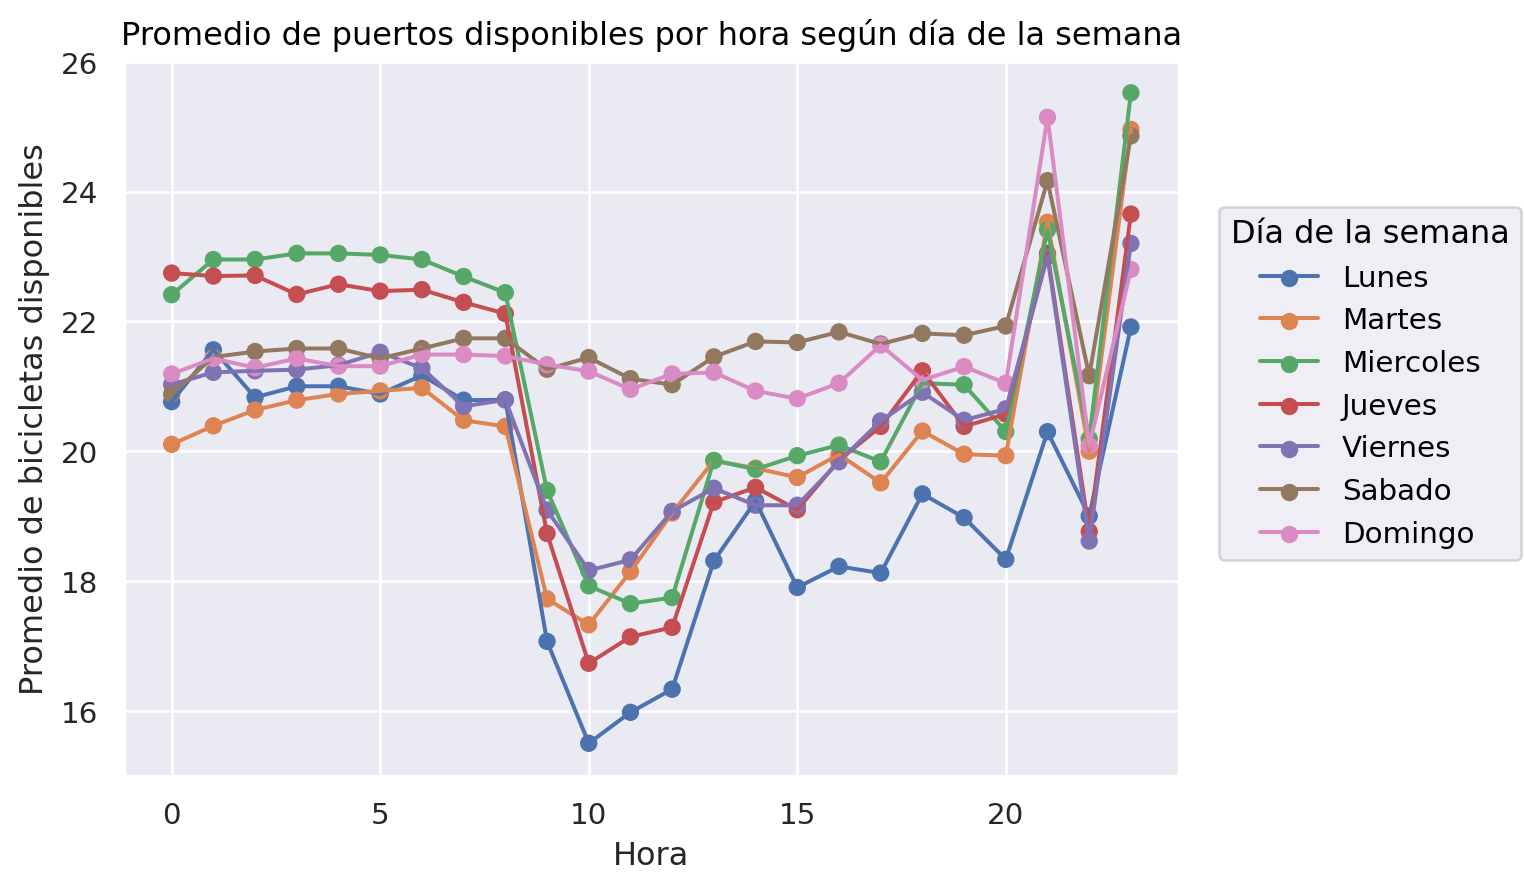

In [17]:
(
    so.Plot(data=datos_agrupados, x="hora", color="dia_semana")
    .add(so.Line(), so.Agg("mean"), y="cantidad_puertos_disponibles")
    .add(so.Dot(), so.Agg("mean"), y="cantidad_puertos_disponibles")
    .label(
        x="Hora",
        y="Promedio de bicicletas disponibles",
        title="Promedio de puertos disponibles por hora según día de la semana",
        color="Día de la semana"
    )
)


En los gráficos realizados en el inciso 11 se puede observar también un valle en disponibilidad de bicicletas (o pico en disponibilidad de puertos) sospechosamente pronunciado en las 21 hs. todos los días, ubicado demasiado tarde en la jornada como para poder ser explicado principalmente por la llegada de estudiantes al campus. Para intentar dilucidar las razones de este valor aparentemente atípico, se realiza un análisis más detallado usando las curvas de promedio de bicicletas disponibles en las dos estaciones (420 y 464) por separado:

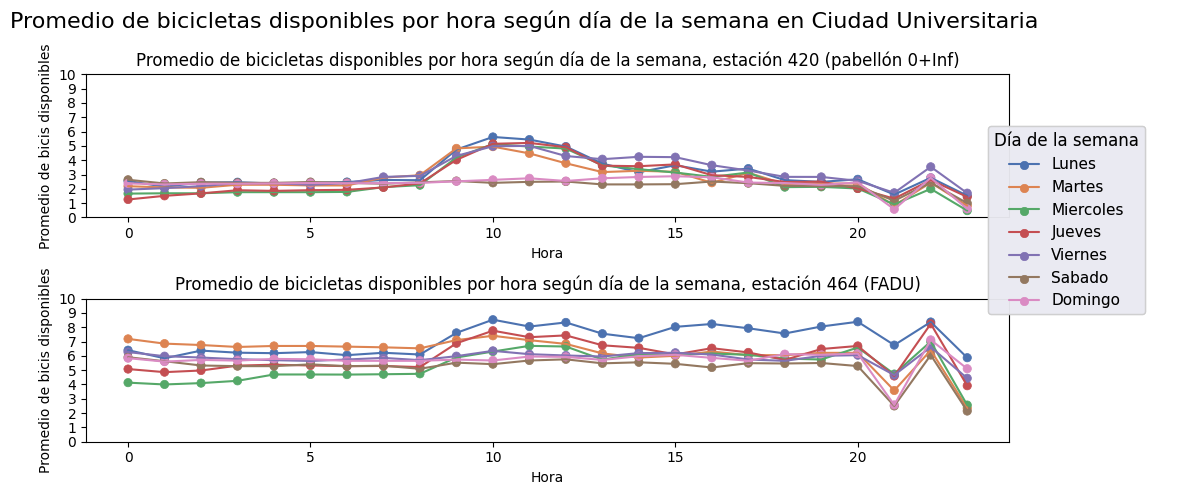

In [18]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(10, 5))
axs_desplegados = axs.ravel()

params = [
    {"data":datos_limpios[datos_limpios["estacion"] == 420], "fin_titulo":", estación 420 (pabellón 0+Inf)"},
    {"data":datos_limpios[datos_limpios["estacion"] == 464], "fin_titulo":", estación 464 (FADU)"}
]

for axs_idx in np.arange(0,2):
    p = (
        so.Plot(data=params[axs_idx]["data"], x="hora", color="dia_semana")
        .add(so.Line(), so.Agg("mean"), y="bicis_disponibles")
        .add(so.Dot(), so.Agg("mean"), y="bicis_disponibles")
        .label(
            x="Hora",
            y="Promedio de bicis disponibles",
            title="Promedio de bicicletas disponibles por hora según día de la semana"+params[axs_idx]["fin_titulo"],
            color="Día de la semana"
        )
        .on(axs_desplegados[axs_idx])
        .plot()
    )
    axs_desplegados[axs_idx].set_yticks(np.arange(0, 11))

fig.suptitle("Promedio de bicicletas disponibles por hora según día de la semana en Ciudad Universitaria", fontsize=16)
plt.tight_layout()
plt.show()

Puede observarse que los valles en las 21 hs. se presenta en todas las curvas (incluso para los sábados y domingos), tanto en el pabellón 0 + Infinito (estación 420) como en la FADU (estación 464). Esto sugiere que la explicación difícilmente provenga de alguna particularidad en los patrones del flujo de estudiantes de alguna facultad, y que quizás habría que buscar causas en algún fenómeno que afecte a ambas por igual. De estos fenómenos más "universales", podría hipotetizarse que alguno de índole climática sea el causante, para lo cual se realizan los siguientes gráficos que muestran el promedio de bicicletas disponibles por hora para cada estación del año:

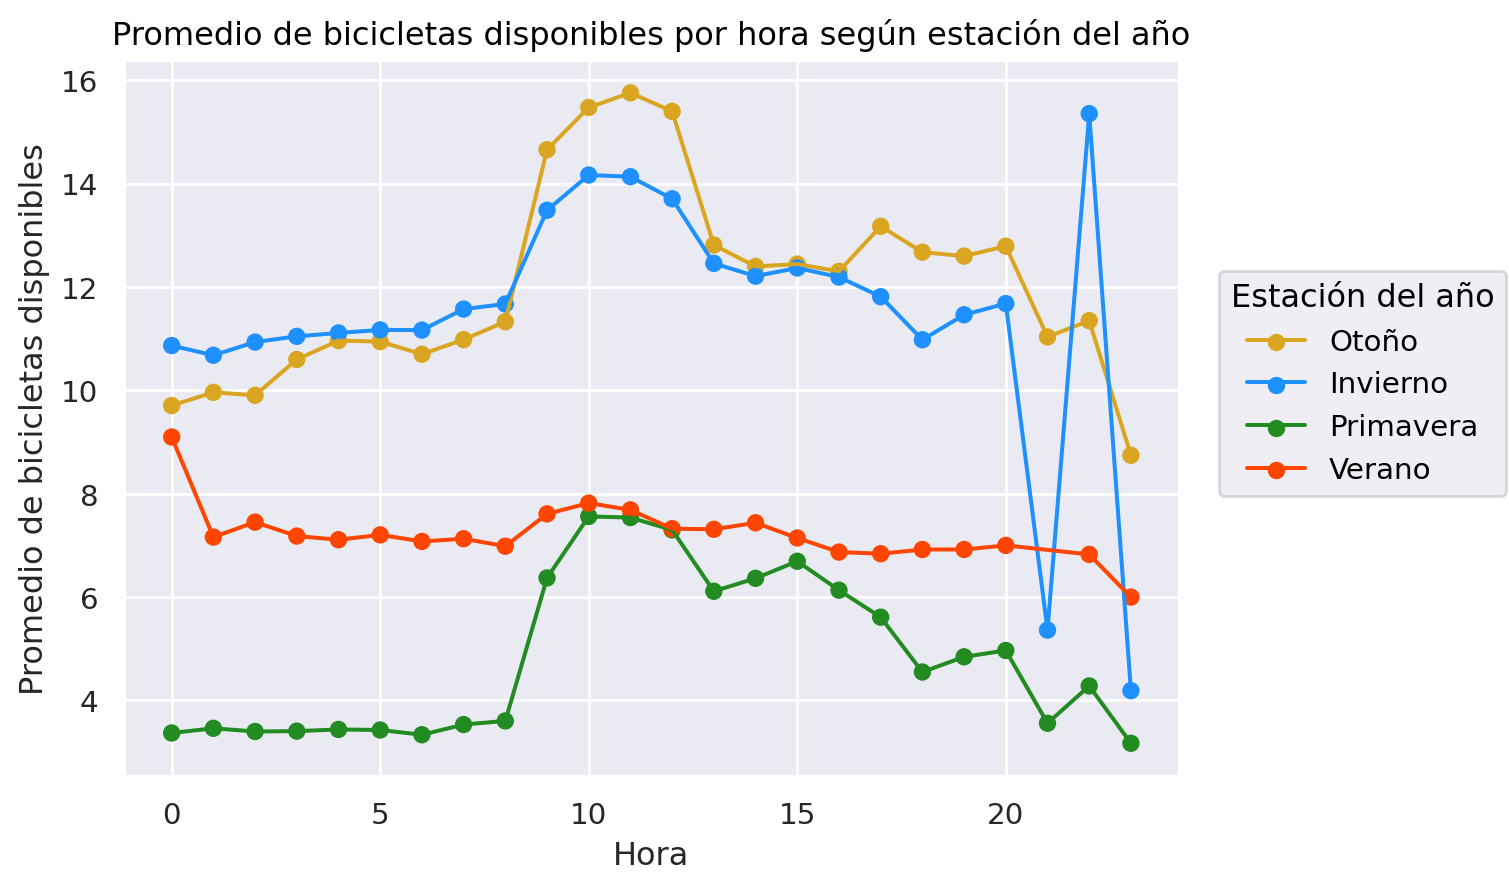

In [19]:
(
    so.Plot(data=datos_agrupados, x="hora", color="estacion_anio")
    .add(so.Line(), so.Agg("mean"), y="cantidad_bicis_disponibles")
    .add(so.Dot(), so.Agg("mean"), y="cantidad_bicis_disponibles")
    .scale(color={"Verano":"orangered","Otoño":"goldenrod","Invierno":"dodgerblue","Primavera":"forestgreen"})
    .label(
        x="Hora",
        y="Promedio de bicicletas disponibles",
        title="Promedio de bicicletas disponibles por hora según estación del año",
        color="Estación del año"
    )
)

Se puede observar que el valle atípico de las 21 hs. puede identificarse en las estaciones de otoño, primavera e invierno, aunque aparece mucho más marcadamente en la última (posiblemente porque, como fue sugerido previamente para el análisis de la disponibilidad en las estaciones, es en invierno en que es más probable que los estudiantes dejen más bicicletas estacionadas en el campus al final del día). También resulta relevante que este valle es inmediatamente sucedido (a las 22 hs.) por un pico similarmente marcado. El hecho de que este comportamiento atípico de la curva al final del día se presente en prácticamente todas las estaciones del año (salvo verano) sugiere que hay algún otro factor "universal" que afecte a las dos estaciones en Ciudad Universitaria. Una posible hipótesis es que la causa se encuentre en el mantenimiento de las bicicletas por parte de técnicos del Gobierno de la Ciudad: la explicación sería que un lote de bicicletas (rotas o simplemente en malas condiciones) son retiradas de las estaciones para mantenimiento y/o reparación alrededor de las 21 hs., siendo reemplazadas por un nuevo lote (no necesariamente el mismo que fue retirado) a las 22 hs. Luego, el mínimo de disponibilidad de bicicletas (o máximo de disponibilidad de puertos) al que se llega generalmente a las 23 hs. podría explicarse por la salida de los estudiantes que cursan a la noche. Otra posible hipótesis es que el valor atípico se deba simplemente a un error de medición del sistema electrónico usado para recopilar los datos de las estaciones (posiblemente una deficiencia en el software o hardware), aunque el hecho de que el error se presente con tanta frecuencia en la misma hora, y que sospechosamente no se presente en verano (donde bajo la otra hipótesis se podría justificar por ausencia de técnicos del Gobierno de la Ciudad por vacaciones) hace que suene menos plausible.

## Análisis exploratorio

En esta sección se dará un análisis en mayor profundidad, donde se intentará responder con mayor certeza a distintas interrogantes que surgen del estudio más superficial del dataset realizado previamente.


#### Análisis preliminar

Antes de iniciar el análisis exploratorio, vale la pena aclarar las condiciones en las que se encuentra actualmente el dataset, estudiando el significado de las columnas disponiblesactualmente:

| Variable | Descripción |
| :--- | :--- |
| **`estacion`** | Identificador único de la estación de bicicletas. Entero de valor mínimo 0. |
| **`bicis_disponibles`** | Número de bicicletas físicamente disponibles para alquilar en la estación. Entero de valor mínimo 0. |
| **`bicis_rotas`** | Número de bicicletas inhabilitadas en la estación. Entero de valor mínimo 0. |
| **`puertos_disponibles`** | Número de puertos funcionales físicamente en la estación. Entero de valor mínimo 0. |
| **`puertos_rotos`** | Número de puertos vacíos pero inhabilitados en la estación. Entero de valor mínimo 0. |
| **`fecha`** | Fecha de la observación. Timestamp de **`pandas.Timestamp`**. |
| **`horario`** | Hora completa de la observación. Tiempo de **`datetime.time`**. |
| **`dia_semana`** | Día de la observación. String de valor $\texttt{Lunes}$, $\texttt{Martes}$, $\texttt{Miercoles}$, $\texttt{Jueves}$, $\texttt{Viernes}$, $\texttt{Sabado}$, o $\texttt{Domingo}$. |
| **`anio`** | Año de la observación. Entero. |
| **`mes`** | Mes de la observación. Entero de valor mínimo 1 y máximo 12. |
| **`dia`** | Día de la observación. Entero de valor mínimo 1 y máximo 31. |
| **`hora`** | Hora de la observación. Entero de valor mínimo 0 y máximo 23. |
| **`estacion_anio`** | Estación del año de la observación. String de valor $\texttt{Verano}$, $\texttt{Otoño}$, $\texttt{Invierno}$ o $\texttt{Primavera}$. |

Para tener una idea de cómo podría verse el flujo de las variables (columnas) en algún día de la semana, se pueden filtrar los datos para un fecha y estación específica, como a continuación:

In [20]:
datos_limpios.loc[datos_limpios["fecha"] == pd.Timestamp("2025-04-29")].loc[datos_limpios["estacion"] == 420]

,estacion,bicis_disponibles,bicis_rotas,puertos_disponibles,puertos_rotos,fecha,horario,dia_semana,anio,mes,dia,hora
2,420,5,1,6,1,2025-04-29,00:32:59,Martes,2025,4,29,0
4,420,5,1,6,1,2025-04-29,01:13:46,Martes,2025,4,29,1
6,420,5,1,6,1,2025-04-29,02:12:38,Martes,2025,4,29,2
8,420,5,1,6,1,2025-04-29,03:17:39,Martes,2025,4,29,3
10,420,5,1,6,1,2025-04-29,04:12:52,Martes,2025,4,29,4
12,420,5,1,6,1,2025-04-29,05:17:18,Martes,2025,4,29,5
14,420,5,1,6,1,2025-04-29,06:13:17,Martes,2025,4,29,6
16,420,7,1,4,1,2025-04-29,07:13:32,Martes,2025,4,29,7
18,420,9,1,2,0,2025-04-29,08:10:14,Martes,2025,4,29,8
20,420,10,1,1,0,2025-04-29,09:23:46,Martes,2025,4,29,9


De buenas a primeras puede observarse que la cantidad de bicicletas disponibles va subiendo hasta estacionarse en su pico en la mañana, alrededor de las 9 y 10 hs., probablemente por coincidir con el comienzo de las primeras clases. Luego, la disponibilidad decrece significativamente a las 13 hs., probablemente por coincidir con la salida de los estudiantes que ingresaron a la clase más temprano, y este proceso se repite (con picos y mesetas menos pronunciadas a la tarde y a la noche, alrededor de las 17 y 20 hs.) hasta alrededor de las 24 hs., donde concretamente puede verse que para alrededor de las 21 y 23 hs. prácticamente no quedan bicicletas disponibles. Las bicicletas rotas se mantienen generalmente estacionarias.

Los puertos disponibles exhiben cambios "inversos" a los de las bicicletas disponibles (dado que una bicicleta que sale de la estación es un nuevo puerto que se libera, y viceversa). Similar a como ocurre con las bicicletas, la cantidad de puertos rotos se mantenienen generalmente estacionaria, en valores cercanos a 0.

Buscando ver si este análisis se sostiene en promedio, se realizan los siguientes cuatro gráficos para la estación 420 (ubicada en las inmediaciones del pabellón Cero más Infinito, al que suelen concurrir principalmente los estudiantes y docentes de la FCEN):

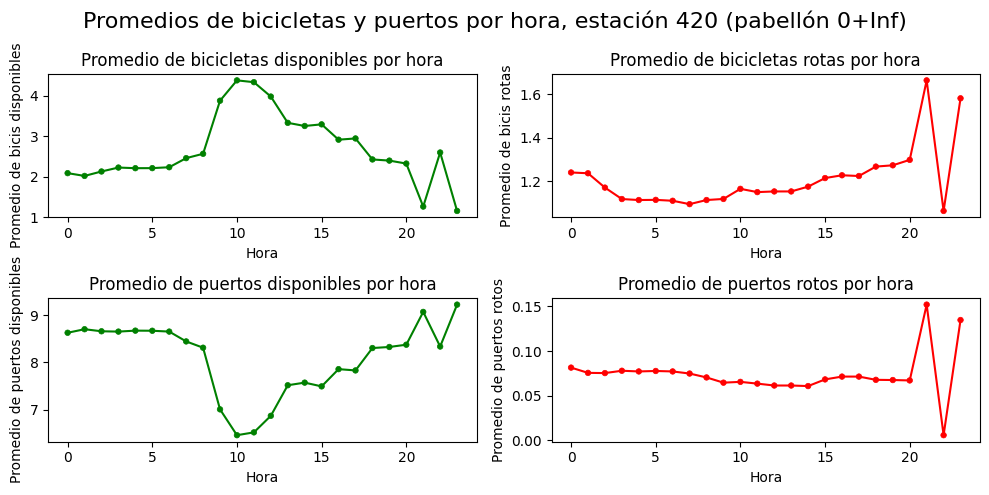

In [21]:
datos_limpios_e420 = datos_limpios[datos_limpios["estacion"] == 420]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 5))
axs_desplegados = axs.ravel()

params = [
    {"y":"bicis_disponibles", "titulo":"Promedio de bicicletas disponibles por hora",
     "ylabel":"Promedio de bicis disponibles", "color":"green"}, 
    {"y":"bicis_rotas", "titulo":"Promedio de bicicletas rotas por hora",
     "ylabel":"Promedio de bicis rotas", "color":"red"},
    {"y":"puertos_disponibles", "titulo":"Promedio de puertos disponibles por hora",
     "ylabel":"Promedio de puertos disponibles", "color":"green"},
    {"y":"puertos_rotos", "titulo":"Promedio de puertos rotos por hora",
     "ylabel":"Promedio de puertos rotos", "color":"red"}
]

for axs_idx in np.arange(0,4):
    (
        so.Plot(data=datos_limpios_e420, x="hora")
        .add(so.Line(color=params[axs_idx]["color"]), so.Agg("mean"), y=params[axs_idx]["y"])
        .add(so.Dot(color=params[axs_idx]["color"], pointsize=4), so.Agg("mean"), y=params[axs_idx]["y"])
        .label(
            x="Hora",
            y=params[axs_idx]["ylabel"],
            title=params[axs_idx]["titulo"],
        )
        .on(axs_desplegados[axs_idx])
        .plot()
    )

fig.suptitle("Promedios de bicicletas y puertos por hora, estación 420 (pabellón 0+Inf)", fontsize=16)
plt.tight_layout()
plt.show()

Se puede notar que, en general, el promedio de bicicletas disponibles respeta el comportamiento observado previamente: un incremento en la disponibilidad hasta aproximadamente las 9 o 10 hs., seguido de picos menos pronunciados en las próximas horas (alrededor de las 15 y 17 hs.), consistentes con los horarios usuales de inico  de clases. El promedio de puertos disponibles es un "espejo" o "inversión" de lo observado para las bicicletas, donde sus valles se corresponden con los picos de disponibilidad de bicicletas y viceversa (nuevamente explicado por la relación inversa que hay entre bicicletas y puertos disponibles, como se señaló previamente).

Por otro lado, y como era de esperar, los promedios de bicicletas y puertos rotos se mantienen generalmente estacionarios, aunque se puede observar (por los valores en el eje de las ordenadas) que suele haber más bicicletas rotas que puertos rotos (probablemente porque las bicicletas se usan mucho más) y que ambos perciben picos de reportes de roturas (o defectuosidad) a las 21 hs. Una hipótesis para explicar esta particularidad se basa en observar que este pico de roturas a las 21 hs. coincide en tiempo con un valle de disponibilidad de bicicletas (y puertos), que previamente (en el inciso 12) se hipotetizó podría deberse a tareas de mantenimiento. Esto sugiere que quizás son los operarios y técnicos del Gobierno de la Ciudad quienes, al acercarse a las estaciones alrededor de las 20 hs., reportan bicicletas y puertos rotos que no hayan sido reportados por los usuarios, conduciendo a un incremento en el promedio de reportes de roturas que luego en la hora siguiente (las 21 hs.). Inmediatamente después, los retiran para mantenimiento (explicando así también el valle a las 21 hs. en la curva de disponibilidad). Finalmente, una vez realizado el mantenimiento a las 22 hs., se repondrían las estaciones con equipos reparados o en mejor estado (tanto bicicletas como puertos) alrededor de las 23 hs., resultando en un promedio de equipos rotos en esta hora ligeramente menor al que se observa a las 21 hs. El mínimo de disponibilidad de bicicletas a las 23 hs. generalmente se podría explicar por la salida de los estudiantes que cursan a la noche (que se van en bicicletas que no están rotas, de modo que no afectan el promedio de bicicletas rotas).

Para la estación 464 se observan curvas de características similares:

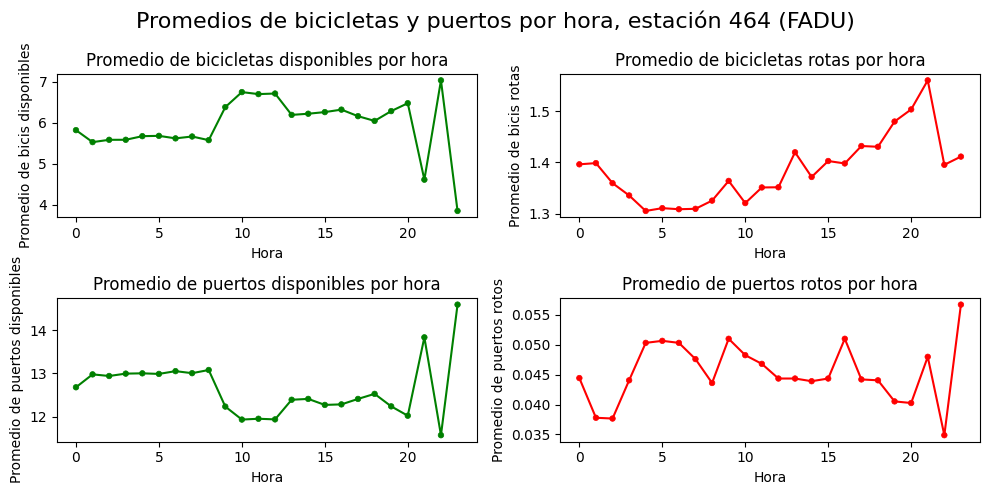

In [22]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 5))

datos_limpios_e464 = datos_limpios[datos_limpios["estacion"] == 464]

axs_desplegados = axs.ravel()
params = [
    {"y":"bicis_disponibles", "titulo":"Promedio de bicicletas disponibles por hora",
     "ylabel":"Promedio de bicis disponibles", "color":"green"}, 
    {"y":"bicis_rotas", "titulo":"Promedio de bicicletas rotas por hora",
     "ylabel":"Promedio de bicis rotas", "color":"red"},
    {"y":"puertos_disponibles", "titulo":"Promedio de puertos disponibles por hora",
     "ylabel":"Promedio de puertos disponibles", "color":"green"},
    {"y":"puertos_rotos", "titulo":"Promedio de puertos rotos por hora",
     "ylabel":"Promedio de puertos rotos", "color":"red"}
]

for axs_idx in np.arange(0,4):
    (
        so.Plot(data=datos_limpios_e464, x="hora")
        .add(so.Line(color=params[axs_idx]["color"]), so.Agg("mean"), y=params[axs_idx]["y"])
        .add(so.Dot(color=params[axs_idx]["color"], pointsize=4), so.Agg("mean"), y=params[axs_idx]["y"])
        .label(
            x="Hora",
            y=params[axs_idx]["ylabel"],
            title=params[axs_idx]["titulo"],
        )
        .on(axs_desplegados[axs_idx])
        .plot()
    )

fig.suptitle("Promedios de bicicletas y puertos por hora, estación 464 (FADU)", fontsize=16)
plt.tight_layout()
plt.show()

Las principales diferencias en las curvas que trazan los datos para la estación 464 son las siguientes:
* Hay una mayor cantidad de bicicletas y puertos disponibles por hora en general (lo cual sugiere quizás un menor uso del sistema en la FADU), y, notoriamente, una mayor frecuencia de rotura de puertos (aunque, considerando la escala del eje de las ordenadas, esta diferencia no resulta numéricamente significativa). Esto último, como se especula más adelante, podría deberse a un error en el sistema de reporte de roturas. 
* El mayor pico de ocupación de puertos (o disponibilidad de bicicletas) en la FADU se da más cerca de las 12 hs., mientras que en el pabellón 0+Infinito se suele dar a las 10 hs.
* El promedio de puertos rotos a las 23 hs. es mayor que a las 21 hs. (a diferencia de lo que ocurre para la otra estación, la 420), a pesar de las tareas de mantenimiento que se hipotetizó previamente se llevan a cabo a las 22 hs. Es posible que haya sido provocado por una cantidad significativa de valores atípicos registrados para la cantidad de puertos rotos a las 23 hs., distorsionando el promedio. Más aún, dado lo erráticos que parecen ser en general los promedios para la cantidad de puertos rotos en la estación 464, se podría sospechar alguna deficiencia en el sistema de reporte de roturas.
* Los picos y valles para los promedios de disponibilidad en la FADU son menos pronunciados que para el pabellón 0+Infinito, lo cual podría explicarse por una  mayor duración, o posiblemente mayor solapamiento de horarios, en los distintos cursos dictados en la facultad (haciendo así menos notorias las idas y venidas de alumnos, por ser su flujo más "continuo" o menos "estructurado" que para el pabellón 0+Infinito).

A continuación, para afinar el análisis realizado en el inciso 12 (en que se discutió la disponibilidad de bicicletas para cada estación del año) se estudia a continuación un boxplot con la disponibilidad de bicicletas por mes (tener en cuenta que los puntos negros en el boxplot representan la media para cada mes):

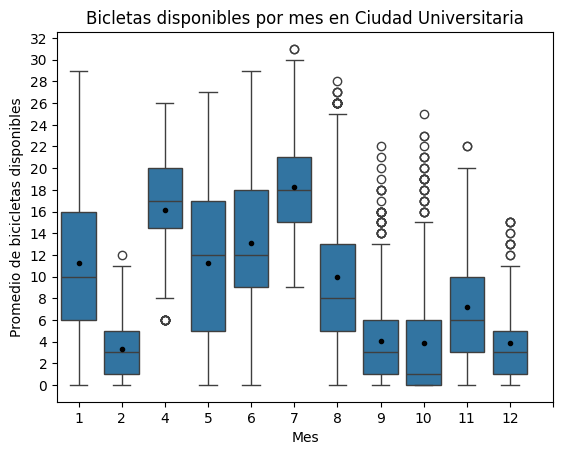

In [23]:
axs = sns.boxplot(
    data=datos_agrupados, x="mes", y="cantidad_bicis_disponibles",  
    # kwargs (de matplotlib) para mostrar la media en cada caja:
    showmeans=True, meanprops={'marker':'o','markeredgecolor':'black','markerfacecolor':'black','markersize':'3'}
)
axs.set_xlabel("Mes")
# Corregir, falta que muestre el mes 3 vacío (no hay observaciones en Marzo):
axs.set_xticks(np.arange(0, 12))
axs.set_ylabel("Promedio de bicicletas disponibles")
axs.set_yticks(np.arange(datos_agrupados["cantidad_bicis_disponibles"].min(), 
                            datos_agrupados["cantidad_bicis_disponibles"].max() + 2, 2))
axs.set_title("Bicletas disponibles por mes en Ciudad Universitaria");

En general, se observa lo que ya se sospechaba en base al análisis por estaciones del año: se observa un pico de actividad al inicio de los primeros cuatrimestres (desde el 17/3 hasta el 5/7 en 2025 y desde 31/3 hasta 17/7 en 2025 para la FCEN y FADU, respectivamente) en los meses 4, 5, 6 y 7 (no hay información para el mes 3), un descenso marcado alrededor del receso de invierno, los cursos de invierno y el inicio del segundo cuatrimestre en el mes 8, y un leve incremento progresivo una vez iniciados los segundos cuatrimestres (desde el 18/8 hasta el 6/12 en 2025 y desde 11/8 hasta 4/12 en 2025 para la FCEN y FADU, respectivamente) en los meses 9, 10, 11 y 12, llegando a sus "picos" en los meses 8 y 11 (que corresponden con el inicio y el cierre de los segundos cuatrimestres). Por otro lado, los "meses de verano" (12, 1 y 2) presentan generalmente poca actividad, aunque con un notable pico en el mes 1, probablemente por coincidir con el inicio de los cursos de verano.

Vale la pena resaltar también lo erráticos que son los valores en la segunda mitad del año, cartacterizados por meses con cajas muy dispares y con muchos valores atípicos, lo cual ayuda a entender un poco mejor los bajos niveles de actividad previamente discutidos para la primavera.

Hilando aún más fino, se puede analizar la disponibilidad de bicicletas por semana:

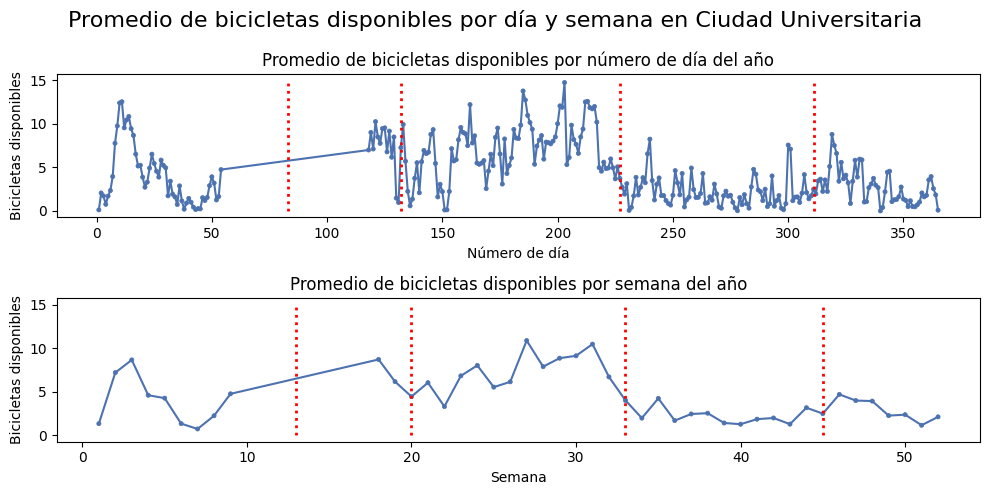

In [24]:
dia_inicio_1c, dia_fin_1c       = pd.Timestamp("24-03-2025").dayofyear, pd.Timestamp("11-07-2025").dayofyear
semana_inicio_1c, semana_fin_1c = pd.Timestamp("24-03-2025").weekofyear, pd.Timestamp("11-07-2025").weekofyear
dia_inicio_2c, dia_fin_2c       = pd.Timestamp("15-08-2025").dayofyear, pd.Timestamp("05-12-2025").dayofyear
semana_inicio_2c, semana_fin_2c = pd.Timestamp("15-08-2025").weekofyear, pd.Timestamp("05-12-2025").weekofyear

lineas_cuat_dia    = [dia_inicio_1c, dia_fin_1c, dia_inicio_2c, dia_fin_2c] 
lineas_cuat_semana = [semana_inicio_1c, semana_fin_1c, semana_inicio_2c, semana_fin_2c]

datos_limpios["dia_anio"] = datos_limpios["fecha"].apply(lambda ts: ts.dayofyear) 
datos_limpios["semana"]   = datos_limpios["fecha"].apply(lambda ts: ts.weekofyear) 
datos_agrupados_dia_anio = datos_limpios.groupby(["dia_anio"], as_index=False).agg({"bicis_disponibles" : "mean"})
datos_agrupados_semana   = datos_limpios.groupby(["semana"], as_index=False).agg({"bicis_disponibles" : "mean"})

params = [
    {"data":datos_agrupados_dia_anio, "x":"dia_anio", 
     "titulo_fin":"número de día del año", "xlabel":"Número de día", "xlineas":lineas_cuat_dia},
    {"data":datos_agrupados_semana, "x":"semana", 
     "titulo_fin":"semana del año", "xlabel":"Semana", "xlineas":lineas_cuat_semana}
]

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(10, 5))
axs_desplegados = axs.ravel()
for axs_idx in np.arange(0,2):
    (
        so.Plot(data=params[axs_idx]["data"], x=params[axs_idx]["x"])
        .add(so.Line(), y="bicis_disponibles")
        .add(so.Dot(pointsize=3), y="bicis_disponibles")
        .label(
            x=params[axs_idx]["xlabel"],
            y="Bicicletas disponibles",
            title="Promedio de bicicletas disponibles por " + params[axs_idx]["titulo_fin"]
        )
        .on(axs_desplegados[axs_idx])
        .plot()
    )
    for x in params[axs_idx]["xlineas"]:
        axs_desplegados[axs_idx].vlines(
            x, ymin=0, ymax=15, 
            colors="red", linestyles="dotted", linewidth=2, zorder=5
        )

fig.suptitle("Promedio de bicicletas disponibles por día y semana en Ciudad Universitaria", fontsize=16)
plt.tight_layout()
plt.show()

Las líneas verticales punteadas marcan el inicio y final del primer y segundo cuatrimestre (promediadas con las fechas para la FCEN y la FADU).

En primer lugar, vale la pena señalar el agujero de datos que se presenta desde la semana 6 a la 17. Sin embargo, más allá de este bache, se observa en general lo mismo que para el gráfico de disponibilidad por mes: una primera mitad con valores generalmente altos, seguidos de una segunda mitad con valores bajos (aproximadamente después de llagar a su pico en la semana 31). En estos gráficos también se evidencian las tendencias identificadas previamente: una disponibilidad relativamente alta cerca del inicio de los dos cuatrimestres, que suele menguar por la mitad y volver a incrementar hacia el final (particularmente notorio para el segundo cuatrimestre, dada la relativa falta de información para el primero).


#### Análisis en profunidad

Para iniciar esta etapa del análisis, se estudia si cualquier cantidad de agua es suficiente para desalentar el uso de las bicicletas o si existe un umbral de tolerancia por parte de los usuarios. Se sospecha que el volumen de viajes no caerá de forma lineal: la idea es que una llovizna leve no alterará significativamente la rutina de los estudiantes, pero que al alcanzar niveles de lluvia moderada o fuerte, el sistema de EcoBici dejará de ser una alternativa viable y la demanda se desploma.

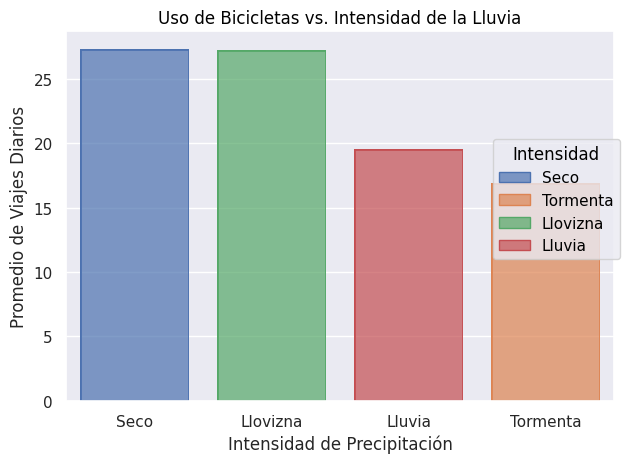

In [25]:
df = pd.read_csv("https://raw.githubusercontent.com/FedeGiovannetti/Eco_bici_Ciudad_Universitaria/refs/heads/main/data/full_data.csv")

df['timestamp'] = pd.to_datetime(df['Date'] + ' ' + df['hora'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
df = df.sort_values(['station_id', 'timestamp'])

df['inventario'] = df['num_bikes_available'] + df['num_bikes_disabled']
df['viajes'] = df.groupby('station_id')['inventario'].diff().abs().fillna(0)

df.loc[df['viajes'] > 10, 'viajes'] = 0

viajes_diarios = df.groupby('Date')['viajes'].sum().reset_index()

df_clima = pd.read_csv('clima.csv')
df_clima['fecha'] = pd.to_datetime(df_clima['fecha']).dt.strftime('%Y-%m-%d')

df_estudio = pd.merge(viajes_diarios, df_clima, left_on='Date', right_on='fecha')

intervalo_prcp = [-1, 0, 3, 10, 100]
labels = ['Seco', 'Llovizna', 'Lluvia', 'Tormenta']

df_estudio['Intensidad'] = pd.cut(df_estudio['prcp'], bins=intervalo_prcp, labels=labels)

grafico_intensidad = (
    so.Plot(df_estudio, x="Intensidad", y="viajes", color="Intensidad")
    .add(so.Bar(), so.Agg("mean"))
    .label(
        title="Uso de Bicicletas vs. Intensidad de la Lluvia",
        x="Intensidad de Precipitación",
        y="Promedio de Viajes Diarios"
    )
)
grafico_intensidad.show()

A partir de los datos procesados, se observa que la llovizna parece no impactar realmente en el uso de las bicicletas, manteniendo niveles de viajes muy similares a los de un día seco. Esto sugiere que los usuarios están dispuestos a tolerar una precipitación mínima para completar sus trayectos.

Sin embargo, el escenario cambia cuando la intensidad aumenta: la lluvia sí genera un impacto marcado, reduciendo el promedio de viajes de forma considerable. Por último, en condiciones de tormenta, el uso cae un poco más, llegando a los niveles mínimos de la serie.

Por otro lado, se busca entender cómo se distribuye la demanda a lo largo de la semana. La principal hipótesis es que el uso del sistema está totalmente supeditado al calendario universitario: se espera ver niveles de actividad altos y sostenidos de lunes a viernes, y una caída drástica durante los sábados y domingos, dado que el flujo de personas en el campus disminuye significativamente fuera de los días hábiles.

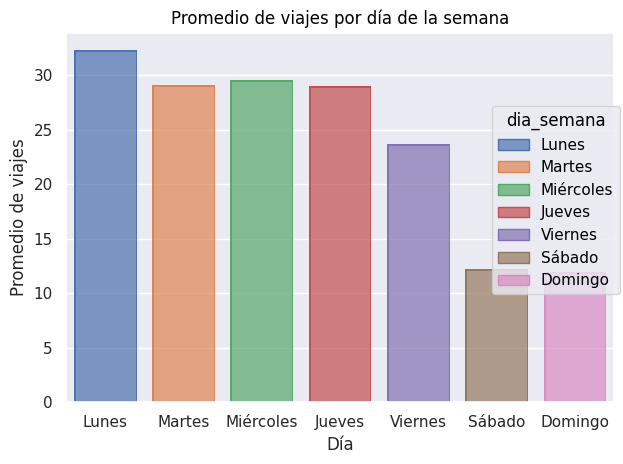

In [26]:
df = pd.read_csv("https://raw.githubusercontent.com/FedeGiovannetti/Eco_bici_Ciudad_Universitaria/refs/heads/main/data/full_data.csv")
df['timestamp'] = pd.to_datetime(df['Date'] + ' ' + df['hora'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
df = df.sort_values(['station_id', 'timestamp'])

df['inventario'] = df['num_bikes_available'] + df['num_bikes_disabled']
df['viajes'] = df.groupby('station_id')['inventario'].diff().abs().fillna(0)
df.loc[df['viajes'] > 10, 'viajes'] = 0

dias_espanyol = {
    'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles',
    'Thursday': 'Jueves', 'Friday': 'Viernes', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}

df['dia_semana'] = df['timestamp'].dt.day_name().map(dias_espanyol)
orden_dias= ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

viajes_por_dia = df.groupby(['Date', 'dia_semana'])['viajes'].sum().reset_index()

grafico_semanal = (
    so.Plot(viajes_por_dia, x="dia_semana", y="viajes", color="dia_semana")
    .add(so.Bar(), so.Agg("mean"))
    .scale(x=so.Nominal(order=orden_dias))
    .label(
        legend=False,
        title="Promedio de viajes por día de la semana",
        x="Día",
        y="Promedio de viajes"
    )
)

grafico_semanal.show()

Los resultados validan la hipótesis de forma contundente: existe una dependencia absoluta entre el uso del sistema y los días hábiles. Se observa que de lunes a viernes el promedio de viajes se mantiene en una meseta alta, lo que indica que la demanda es constante durante toda la semana de cursada.

## Regresión lineal

En esta última sección se analiza el uso de bicicletas en otras estaciones de la Ciudad de Buenos Aires, utilizando un dataset distinto. Para ello, se ajustarán modelos de regresión lineal.


Se busca ajstar la cantidad de viajes con origen en la estación 005 (*Plaza Italia*) en función de viajes originados en otras estaciones o con destino en distintas estaciones. Concretamente, se busca ajustar la bariable **`origen_5`** en función de otras variables del dataset que se carga a continuación:

In [27]:
viajes_diarios = pd.read_csv("viajes_diarios.csv")

display(viajes_diarios)

,fecha,origen_2,origen_3,origen_4,origen_5,origen_6,origen_7,origen_8,origen_9,origen_12,...,destino_567,destino_568,destino_569,destino_570,destino_572,destino_573,destino_574,destino_575,destino_576,destino_577
0,2024-01-01,13,24,39,45,0,27,28,32,20,...,0,0,0,0,0,0,0,0,0,0
1,2024-01-02,27,58,85,123,27,38,90,65,31,...,0,0,0,0,0,0,0,0,0,0
2,2024-01-03,40,67,65,144,33,18,113,71,39,...,0,0,0,0,0,0,0,0,0,0
3,2024-01-04,39,53,66,98,35,42,103,66,35,...,0,0,0,0,0,0,0,0,0,0
4,2024-01-05,27,63,50,84,46,28,93,60,32,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27,25,41,72,103,40,19,81,62,36,...,17,25,31,20,15,11,27,5,33,18
362,2024-12-28,16,19,26,33,10,4,21,23,23,...,8,19,25,29,1,2,5,3,33,6
363,2024-12-29,15,17,15,83,12,8,38,35,26,...,12,23,23,27,7,4,1,1,17,9
364,2024-12-30,26,62,55,123,58,12,96,63,39,...,15,21,47,24,7,4,9,10,34,15


### Inciso 16

A continuación se proponen tres modelos de regresión distintos para lograr el cometido propuesto en el inciso 15.

1. Primero se propone un modelo simple, que explique la cantidad de de viajes originarios **desde** Plaza Italia con la cantidad de viajes **hacia** Plaza Italia. Se espera que estas dos variables esten fuertemente relacionadas, debido a que en general las personas que viaja hacia Plaza Italia tienen que posteriormente volver de ella.
La formula para tal modelo es la siguiente: Origen_5 ~ $β_{0}$+ $β_{1}$*$D_5$  (donde $D$ se refiere a destino y el numero a la estacion). El intercept está para representar gente que se fue desde Plaza Italia y no vuelve.

2. Para el segundo  modelo se utiliza las cantidad de viajes de las cinco estaciones  más cercanas a Plaza Italia, las que están ubicadas a aproximadamente  1 km. Estas estaciones son *Pacifico (14)*, *Ugarteche (124)* , *Ecoparque (44)* , *Plaza Palermo Viejo (56)* y *Juncal (190)*. Las estaciones *Santamaria de Or (125)* y *Guatemala (113)* son las más cercanas a Plaza Italia, pero no se encuentran en el data set. 
La formula para este segundo modelo es la siguiente: Origen_5 ~ $β_0$ + $β_1$*$D_{14}$ + $β_2$*$D_{124}$ +$β_3$*$D_{44}$ + $β_4$*$D_{56}$ +$β_5$*$D_{190}$.\

3. El tercer modelo se establece eligiendo 5 estaciones al azar, usando la herramienta de RNG (*Random Number Generation*, generación de números aleatorios) de Google. Se usan las estaciones 264, 427, 58, 433 y 400.


Para la comparacion de modelos se siguen los siguientes pasos:
1. Primero se divide los datos en en train y test.
2. Luego, una vez separado, se utiliza validación cruzada de k pliegos (folds). La misma consiste en dividir el dataset de entrenamiento en k partes iguales y luego evaluar el modelo k veces. En cada evaluación, de manera rotativa, se usa una partición para validar y las otras para entrenar.
3. A continuación, se mide el RMSE (*Root-Mean-Squared Error*) promedio entre las evaluaciones.
4. Se repiten los pasos 1 y 2 para otro modelo y se conxerva el modelo que minimice el RMSE.
5. Por último, ajustamos el modelo "ganador" para un test final en todo el data set de entrenamiento y luego se hace una prediccion y comparación con los datos de testeo.

In [28]:
# Para la comparacion de modelos primero se divide a los datos en train y test:
viajes_diarios_train, viajes_diarios_test = train_test_split(viajes_diarios, test_size=0.2, random_state=20)
cv = KFold(n_splits=5, random_state=20, shuffle=True) # Genera un iterador para los pliegues.

In [29]:
#Modelo 1
Modelo_1_X=viajes_diarios[['destino_5']] # Guarda las variables con las que se predice.
Modelo_1_y=viajes_diarios['origen_5'] # Guarda la variable a predecir.
modelo1 = linear_model.LinearRegression(fit_intercept = True)    # Se inicializa un modelo de Regresión Lineal.
rmse1 = np.zeros(cv.get_n_splits()) # Se crea un array vacío para guardar los rmse de cada iteración.
ind=0
for train_index, val_index in cv.split(Modelo_1_X): # Se crea un ciclo para iterar evaluaciones.
    # Se separa en validación y testeo. iloc permite dejar las filas por posición numérica (ej.: fila 1, fila 2, etc.)
    X_train, X_val, y_train, y_val = Modelo_1_X.iloc[train_index], Modelo_1_X.iloc[val_index],Modelo_1_y.iloc[train_index], Modelo_1_y.iloc[val_index]

    modelo1.fit(X_train, y_train) # Se entrena con el conjunto de entrenamiento.

    y_pred = modelo1.predict(X_val) # Se hace la predicción la predicción sobre los datos de validación.
    rmse1[ind] = np.sqrt(mean_squared_error(y_val, y_pred))  # Se guardan los errores en un vector.
    ind = ind + 1

#Modelo 2
modelo_2_X=viajes_diarios[['destino_14',"destino_124","destino_44","destino_56","destino_190"]]
modelo_2_y=viajes_diarios['origen_5']
modelo2= linear_model.LinearRegression(fit_intercept = True)    # Inicializamos un modelo de Regresion Lineal
rmse2 = np.zeros(cv.get_n_splits()) #Nos creamos un array de 0 para guardar los rmse de cada iteracion
ind=0
for train_index, val_index in cv.split(modelo_2_X):
    X_train, X_val, y_train, y_val = modelo_2_X.iloc[train_index], modelo_2_X.iloc[val_index],modelo_2_y.iloc[train_index], modelo_2_y.iloc[val_index]
    modelo2.fit(X_train, y_train)

    y_pred = modelo2.predict(X_val)
    rmse2[ind] = np.sqrt(mean_squared_error(y_val, y_pred))  # Se guardan los errores en un arreglo.
    ind = ind + 1

#Modelo 3
modelo_3_X=viajes_diarios[["origen_264","origen_427","origen_58","origen_433","origen_400"]]
modelo_3_y=viajes_diarios[["origen_5"]]
modelo3= linear_model.LinearRegression(fit_intercept = True) # Se inicializa un modelo de Regresión Lineal.
rmse3 = np.zeros(cv.get_n_splits()) # Se crea un array de 0 para guardar los rmse de cada iteración.
ind=0
for train_index, val_index in cv.split(modelo_3_X):
    X_train, X_val, y_train, y_val = modelo_3_X.iloc[train_index], modelo_3_X.iloc[val_index],modelo_3_y.iloc[train_index], modelo_3_y.iloc[val_index]
    modelo3.fit(X_train, y_train)

    y_pred = modelo3.predict(X_val)
    rmse3[ind] = np.sqrt(mean_squared_error(y_val, y_pred))  # Se guardan los errores en un vector.
    ind = ind + 1
print(f"El RMSE promedio del modelo 1 es {rmse1.mean()} -> es el menor ")
print(f"El RMSE promedio del modelo 2 es {rmse2.mean()}")
print(f"El RMSE promedio del modelo 3 es {rmse3.mean()}")

El RMSE promedio del modelo 1 es 8.871402286307342 -> es el menor 
El RMSE promedio del modelo 2 es 24.54271937357475
El RMSE promedio del modelo 3 es 29.12950760763969


El modelo 1 fue el que minimizó el RMSE, por lo que es considerado el mejor entre los 3. Cabe destacar que el modelo 2 presenta mejoría respecto al modelo 3, que utilizó un criterio completamente aleatorio.

In [30]:
# Testeo final.
modelo1.fit(Modelo_1_X,Modelo_1_y) # Se ajusta usando todos el conjunto de datos de prueba.
print("Coeficientes ", modelo1.coef_, " e  Intercept " ,modelo1.intercept_)
y_pred = modelo1.predict(viajes_diarios_test[["destino_5"]]) # Se predice usando el conjunto de datos de testeo.
r2 = r2_score(viajes_diarios_test[["destino_5"]], y_pred)
ecm = mean_squared_error(viajes_diarios_test[["destino_5"]], y_pred) # Se calcula el error.
print('Raíz cuadarada del ECM: ', f'{np.sqrt(ecm)} y ','R^2: ', r2)

Coeficientes  [0.99605684]  e  Intercept  0.2116315548620662
Raíz cuadarada del ECM:  0.23713770135597023 y  R^2:  0.9999679260711088
